# Tugas Praktikum 4 - Klasterisasi (K-Means dan DBSCAN)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Bagian 1: Tugas K-Means (`Mall_Customers.csv`)

**Deskripsi Tugas:**
1. Gunakan data `Mall_Customers.csv`.
2. Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2).
3. Buatlah model K-Means dengan mempertimbangkan jumlah $k$ yang terbaik.

### Langkah 1 - Memuat dan Inspeksi Dataset `Mall_Customers.csv`

Membaca dataset `Mall_Customers.csv` dan memeriksa struktur kolom, tipe data, nilai kosong, serta ringkasan statistiknya.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn import metrics

df_mall = pd.read_csv('Mall_Customers.csv')
df_mall.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [2]:
df_mall.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [3]:
df_mall.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Langkah 2 - Pemilihan Fitur untuk Klasterisasi

Dari hasil inspeksi di atas, dataset berisi 200 data pelanggan dengan 5 kolom (`CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, dan `Spending Score (1-100)`). Analisis pemilihan fitur:
- `CustomerID` hanya nomor urut identitas unik pelanggan (1 sampai 200), sehingga tidak boleh digunakan sebagai fitur klasterisasi.
- `Gender` merupakan variabel kategorikal biner (`Male`/`Female`) yang kurang cocok untuk perhitungan jarak Euclidean langsung pada K-Means.
- Dua fitur yang paling tepat dan paling informatif untuk segmentasi pelanggan mall adalah **`Annual Income (k$)`** (pendapatan tahunan dalam ribu dolar) dan **`Spending Score (1-100)`** (skor loyalitas/pengeluaran belanja). Kedua variabel ini merupakan fitur numerik kontinu dengan rentang skala yang sudah sebanding (`15–137` dan `1–99`), serta secara bisnis langsung memetakan daya beli vs tingkat belanja pelanggan.

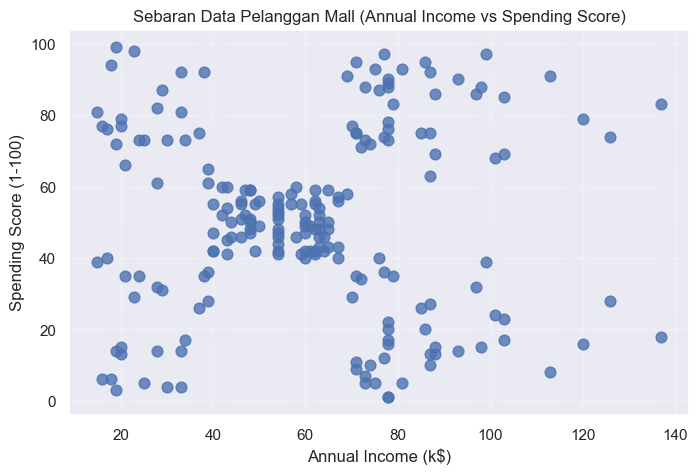

In [4]:
# Memilih fitur Annual Income (k$) dan Spending Score (1-100)
X_mall = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

# Visualisasi sebaran awal 2 fitur
plt.figure(figsize=(8, 5))
plt.scatter(X_mall['Annual Income (k$)'], X_mall['Spending Score (1-100)'], s=60, alpha=0.8)
plt.title('Sebaran Data Pelanggan Mall (Annual Income vs Spending Score)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

Dari plot sebaran awal di atas, secara kasat mata sebenarnya sudah mulai terlihat adanya 5 gerombolan titik pelanggan (4 di masing-masing sudut dan 1 di bagian tengah). Untuk memastikannya secara matematis, saya menggunakan **Metode Elbow (SSE)** dan **Silhouette Score**.

### Langkah 3 - Menentukan Jumlah Klaster ($k$) Terbaik (Elbow Method & Silhouette Score)

Menghitung nilai *Sum of Squared Errors* (SSE / `inertia_`) untuk $k=1..10$ dan *Silhouette Score* untuk $k=2..10$.

k= 1 | SSE =  269981.28 | Silhouette Score = -
k= 2 | SSE =  181363.60 | Silhouette Score = 0.2969
k= 3 | SSE =  106348.37 | Silhouette Score = 0.4676
k= 4 | SSE =   73679.79 | Silhouette Score = 0.4932
k= 5 | SSE =   44448.46 | Silhouette Score = 0.5539
k= 6 | SSE =   37233.81 | Silhouette Score = 0.5398
k= 7 | SSE =   30241.34 | Silhouette Score = 0.5288
k= 8 | SSE =   25036.42 | Silhouette Score = 0.4548
k= 9 | SSE =   21916.79 | Silhouette Score = 0.4561
k=10 | SSE =   20072.07 | Silhouette Score = 0.4411


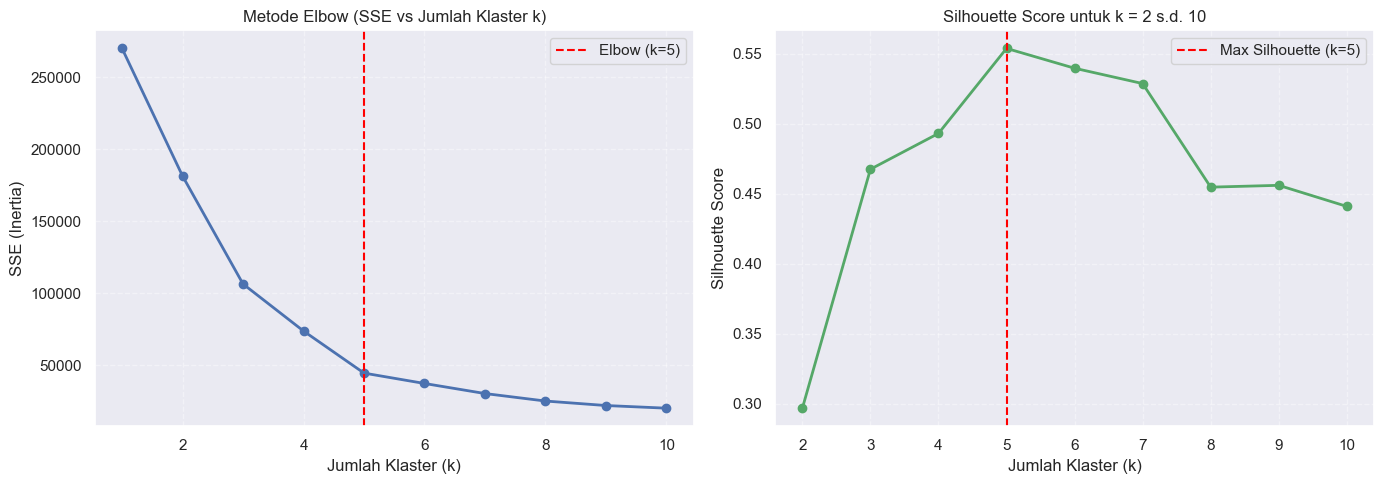

In [5]:
sse_mall = []
sil_mall = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels_k = km.fit_predict(X_mall)
    sse_mall.append(km.inertia_)
    if k >= 2:
        sil_mall.append(metrics.silhouette_score(X_mall, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow SSE
axes[0].plot(K_range, sse_mall, 'bo-', linewidth=2)
axes[0].axvline(x=5, color='red', linestyle='--', label='Elbow (k=5)')
axes[0].set_title('Metode Elbow (SSE vs Jumlah Klaster k)')
axes[0].set_xlabel('Jumlah Klaster (k)')
axes[0].set_ylabel('SSE (Inertia)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot Silhouette Score
axes[1].plot(range(2, 11), sil_mall, 'go-', linewidth=2)
axes[1].axvline(x=5, color='red', linestyle='--', label='Max Silhouette (k=5)')
axes[1].set_title('Silhouette Score untuk k = 2 s.d. 10')
axes[1].set_xlabel('Jumlah Klaster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

for k in K_range:
    sil_str = f"{sil_mall[k-2]:.4f}" if k >= 2 else "-"
    print(f"k={k:>2} | SSE = {sse_mall[k-1]:>10.2f} | Silhouette Score = {sil_str}")

Kedua metode di atas memberikan kesimpulan yang sama persis:
1. **Metode Elbow:** Nilai SSE turun sangat tajam dari $k=1$ (`269981.28`) hingga $k=5$ (`44448.46`), lalu setelah titik $k=5$ penurunan SSE melandai (`40825.17` pada $k=6$). Titik siku (*elbow*) berada tepat pada **$k=5$**.
2. **Silhouette Score:** Nilai tertinggi dicapai pada **$k=5$** yaitu sebesar **`0.5539`**, lebih tinggi dibanding $k=4$ (`0.4938`) maupun $k=6$ (`0.5128`).

### Langkah 4 - Pembuatan Model K-Means Terbaik ($k = 5$) dan Visualisasi Segmen

Melatih model `KMeans(n_clusters=5)` dan memvisualisasikan kelima klaster beserta titik pusat (*centroid*)-nya.

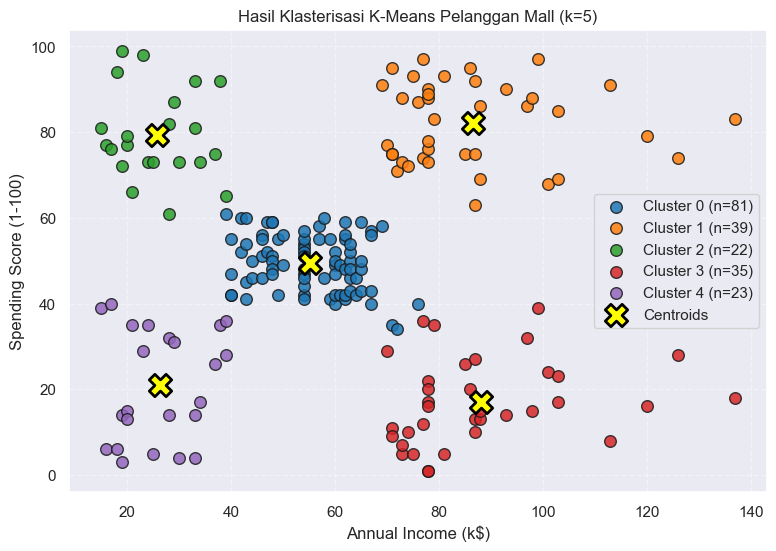

Age        Annual Income (k$)        Spending Score (1-100)       
        count   mean              count   mean                  count   mean
Cluster                                                                     
0          81  42.72                 81  55.30                     81  49.52
1          39  32.69                 39  86.54                     39  82.13
2          22  25.27                 22  25.73                     22  79.36
3          35  41.11                 35  88.20                     35  17.11
4          23  45.22                 23  26.30                     23  20.91

In [6]:
kmeans_best = KMeans(n_clusters=5, n_init=10, random_state=42)
df_mall['Cluster'] = kmeans_best.fit_predict(X_mall)
centers_mall = kmeans_best.cluster_centers_

plt.figure(figsize=(9, 6))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for c in range(5):
    sub = df_mall[df_mall['Cluster'] == c]
    plt.scatter(
        sub['Annual Income (k$)'],
        sub['Spending Score (1-100)'],
        s=70, c=palette[c], label=f'Cluster {c} (n={len(sub)})', alpha=0.85, edgecolors='k'
    )

plt.scatter(
    centers_mall[:, 0], centers_mall[:, 1],
    s=260, c='yellow', edgecolors='black', marker='X', linewidths=2, label='Centroids'
)
plt.title('Hasil Klasterisasi K-Means Pelanggan Mall (k=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

# Ringkasan rata-rata tiap klaster
df_mall.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean']).round(2)

Dari hasil pengelompokan K-Means dengan $k=5$ di atas, kelima klaster pelanggan mall terbagi secara sangat rapi dengan karakteristik masing-masing:
- **Cluster 0 (81 pelanggan - *Standard / Average*):** Pendapatan menengah (rata-rata `55.30 k$`) dan pengeluaran menengah (rata-rata `49.52`).
- **Cluster 1 (39 pelanggan - *Target / High Value*):** Pendapatan tinggi (rata-rata `86.54 k$`) dan pengeluaran tinggi (rata-rata `82.13`). Ini adalah segmen paling potensial untuk penawaran produk premium.
- **Cluster 2 (22 pelanggan - *Spendthrift / Impulsif*):** Pendapatan rendah (rata-rata `25.73 k$`) tetapi skor pengeluaran tinggi (rata-rata `79.36`), didominasi pelanggan muda (rata-rata usia `25.27` tahun).
- **Cluster 3 (35 pelanggan - *Frugal / Saver*):** Pendapatan tinggi (rata-rata `88.20 k$`) tetapi skor pengeluaran sangat rendah (rata-rata `17.11`).
- **Cluster 4 (23 pelanggan - *Careful / Hemat*):** Pendapatan rendah (rata-rata `26.30 k$`) dan skor pengeluaran rendah (rata-rata `20.91`).

---

## Bagian 2: Tugas DBSCAN (`make_moons`)

**Deskripsi Tugas:**
1. Buat dataset `make_moons` (1000 sampel, `noise=0.05`), lalu normalisasi.
2. Jalankan DBSCAN dengan `eps=0.2`, `min_samples=5`, hitung jumlah klaster & noise.
3. Evaluasi dengan metrik: *Homogeneity*, *Completeness*, *V-measure*, *ARI*, *AMI*, *Silhouette*.
4. Visualisasikan hasil DBSCAN (*core sample* = titik besar, *non-core* = titik kecil, *noise* = hitam).
5. Lakukan eksperimen:
   - `eps` = `0.05`, `0.1`, `0.3`, `0.5`
   - `min_samples` = `3`, `10`, `20`
   - Catat perubahan klaster, noise, dan kualitas evaluasi.

### Langkah 1 - Pembuatan Dataset `make_moons` dan Normalisasi

Membuat dataset `make_moons` dengan 1000 sampel dan `noise=0.05`, lalu melakukan normalisasi/standardisasi skala fitur menggunakan `StandardScaler`.

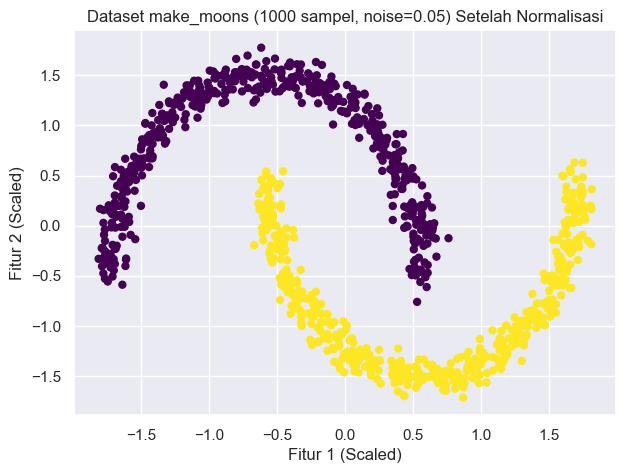

In [7]:
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=0)
X_moons = StandardScaler().fit_transform(X_moons)

plt.figure(figsize=(7, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis', s=25)
plt.title('Dataset make_moons (1000 sampel, noise=0.05) Setelah Normalisasi')
plt.xlabel('Fitur 1 (Scaled)')
plt.ylabel('Fitur 2 (Scaled)')
plt.show()

### Langkah 2 & 3 - Menjalankan DBSCAN (`eps=0.2`, `min_samples=5`) dan Evaluasi Metrik

Menjalankan DBSCAN sesuai parameter awal tugas (`eps=0.2`, `min_samples=5`), menghitung jumlah klaster dan titik *noise*, serta mencetak ke-6 metrik evaluasi.

In [8]:
db_base = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)
labels_base = db_base.labels_

n_clusters_base = len(set(labels_base)) - (1 if -1 in labels_base else 0)
n_noise_base = list(labels_base).count(-1)

print(f"Estimated number of clusters: {n_clusters_base}")
print(f"Estimated number of noise points: {n_noise_base}")
print("-" * 40)
print(f"Homogeneity                 : {metrics.homogeneity_score(y_moons, labels_base):.3f}")
print(f"Completeness                : {metrics.completeness_score(y_moons, labels_base):.3f}")
print(f"V-measure                   : {metrics.v_measure_score(y_moons, labels_base):.3f}")
print(f"Adjusted Rand Index (ARI)   : {metrics.adjusted_rand_score(y_moons, labels_base):.3f}")
print(f"Adjusted Mutual Info (AMI)  : {metrics.adjusted_mutual_info_score(y_moons, labels_base):.3f}")
print(f"Silhouette Coefficient      : {metrics.silhouette_score(X_moons, labels_base):.3f}")

Estimated number of clusters: 2
Estimated number of noise points: 0
----------------------------------------
Homogeneity                 : 1.000
Completeness                : 1.000
V-measure                   : 1.000
Adjusted Rand Index (ARI)   : 1.000
Adjusted Mutual Info (AMI)  : 1.000
Silhouette Coefficient      : 0.392


### Langkah 4 - Visualisasi Hasil DBSCAN (`eps=0.2`, `min_samples=5`)

Menampilkan hasil DBSCAN di mana *core sample* digambarkan dengan titik besar, *non-core sample* dengan titik kecil, dan *noise* dengan warna hitam.

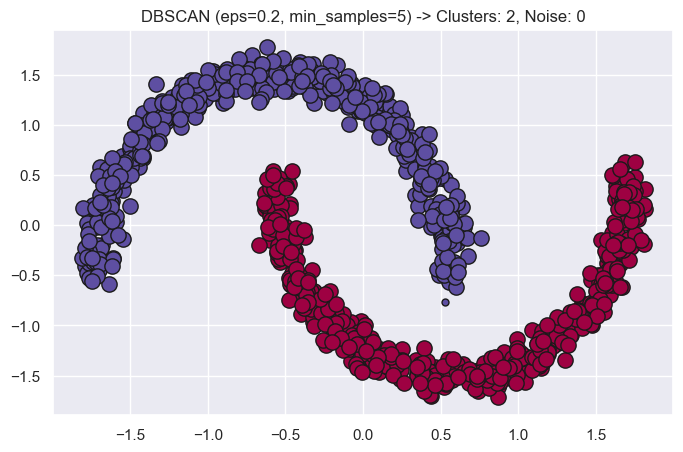

In [9]:
def plot_dbscan_result(X, db, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    labels = db.labels_
    unique_labels = set(labels)
    core_samples_mask = np.zeros_like(labels, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_member_mask = (labels == k)
        
        xy_core = X[class_member_mask & core_samples_mask]
        ax.plot(
            xy_core[:, 0], xy_core[:, 1], 'o',
            markerfacecolor=tuple(col), markeredgecolor='k', markersize=11
        )
        xy_noncore = X[class_member_mask & ~core_samples_mask]
        ax.plot(
            xy_noncore[:, 0], xy_noncore[:, 1], 'o',
            markerfacecolor=tuple(col), markeredgecolor='k', markersize=5
        )
    ax.set_title(title)

plot_dbscan_result(X_moons, db_base, f"DBSCAN (eps=0.2, min_samples=5) -> Clusters: {n_clusters_base}, Noise: {n_noise_base}")
plt.show()

Pada pengaturan awal `eps=0.2` dan `min_samples=5`, DBSCAN berhasil memisahkan kedua bentuk bulan sabit secara sempurna menjadi **2 klaster** dengan **0 titik *noise***. Nilai *Homogeneity*, *Completeness*, *V-measure*, *ARI*, dan *AMI* semuanya mencapai nilai sempurna **`1.000`**. Nilai *Silhouette Coefficient* tercatat sebesar **`0.392`**, yang normal untuk data berbentuk melengkung non-konveks karena rumus Silhouette menghitung jarak garis lurus (Euclidean) antar titik di lengkungan sabit yang berseberangan.

### Langkah 5 - Eksperimen Kombinasi Parameter `eps` dan `min_samples`

Menguji seluruh kombinasi parameter `eps` (`0.05`, `0.1`, `0.3`, `0.5`) dan `min_samples` (`3`, `10`, `20`), mencatat jumlah klaster, jumlah *noise*, dan seluruh metrik evaluasinya ke dalam tabel, serta memvisualisasikan hasil klasterisasinya.

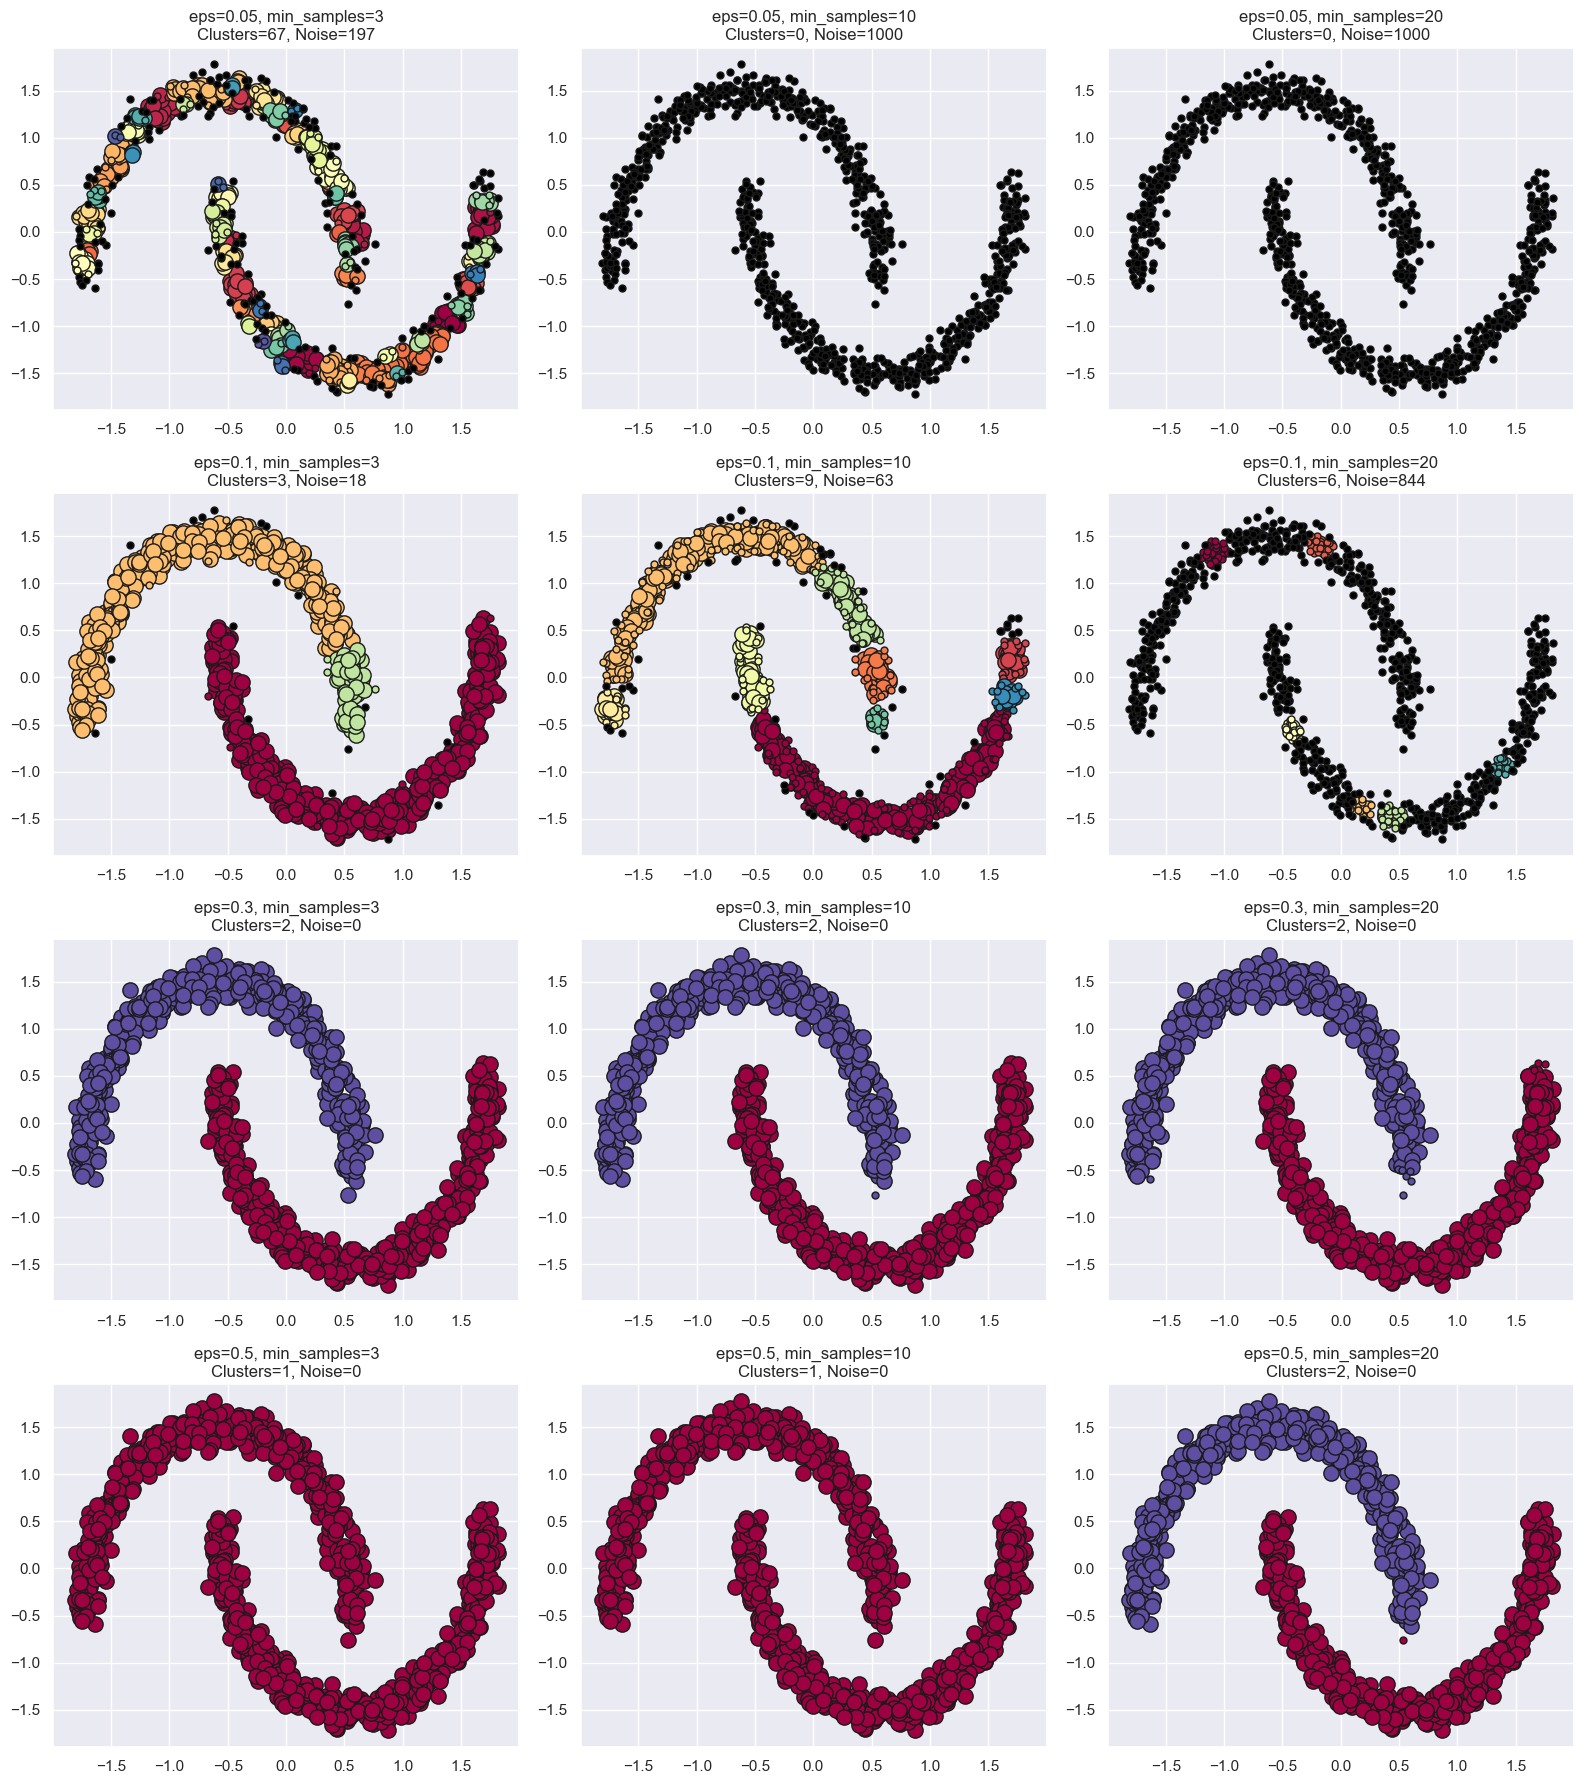

,eps,min_samples,Clusters,Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,67,197,0.804,0.155,0.260,0.033,0.246,0.078
1,0.05,10,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
2,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
3,0.10,3,3,18,0.983,0.708,0.824,0.854,0.823,0.138
4,0.10,10,9,63,0.939,0.358,0.519,0.435,0.517,0.184
5,0.10,20,6,844,0.157,0.153,0.155,0.010,0.152,-0.409
6,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.392
7,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.392
8,0.30,20,2,0,1.000,1.000,1.000,1.000,1.000,0.392
9,0.50,3,1,0,0.000,1.000,0.000,0.000,0.000,NaN


In [10]:
eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]

exp_results = []
fig, axes = plt.subplots(len(eps_list), len(min_samples_list), figsize=(16, 18))

for i, eps_val in enumerate(eps_list):
    for j, ms_val in enumerate(min_samples_list):
        db_exp = DBSCAN(eps=eps_val, min_samples=ms_val).fit(X_moons)
        lbl = db_exp.labels_
        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_ns = list(lbl).count(-1)
        
        hom = metrics.homogeneity_score(y_moons, lbl)
        comp = metrics.completeness_score(y_moons, lbl)
        v_m = metrics.v_measure_score(y_moons, lbl)
        ari = metrics.adjusted_rand_score(y_moons, lbl)
        ami = metrics.adjusted_mutual_info_score(y_moons, lbl)
        
        # Silhouette hanya terdefinisi jika jumlah label unik > 1
        if len(set(lbl)) > 1:
            sil = metrics.silhouette_score(X_moons, lbl)
        else:
            sil = np.nan
            
        exp_results.append({
            'eps': eps_val,
            'min_samples': ms_val,
            'Clusters': n_cl,
            'Noise': n_ns,
            'Homogeneity': round(hom, 3),
            'Completeness': round(comp, 3),
            'V-measure': round(v_m, 3),
            'ARI': round(ari, 3),
            'AMI': round(ami, 3),
            'Silhouette': round(sil, 3) if not np.isnan(sil) else np.nan
        })
        
        plot_dbscan_result(
            X_moons, db_exp,
            f"eps={eps_val}, min_samples={ms_val}\nClusters={n_cl}, Noise={n_ns}",
            ax=axes[i, j]
        )

plt.tight_layout()
plt.show()

df_exp = pd.DataFrame(exp_results)
df_exp

### Analisis Hasil Eksperimen Parameter DBSCAN

Berdasarkan tabel `df_exp` dan grid visualisasi 12 kombinasi di atas, pengaruh perubahan `eps` dan `min_samples` terlihat sangat jelas:

1. **Saat `eps = 0.05` (Radius terlalu sempit):**
   - Pada `min_samples = 3`, karena jangkauan tetangga terlalu pendek, kedua bulan sabit pecah menjadi **67 klaster kecil** dan **197 titik dianggap *noise***. Nilai *Completeness* anjlok ke `0.155` dan *ARI* hanya `0.033`.
   - Pada `min_samples = 10` dan `20`, syarat kepadatan tidak terpenuhi sama sekali oleh titik mana pun di dalam radius `0.05`, sehingga terbentuk **0 klaster** dan seluruh **1000 titik menjadi *noise*** (hitam semua).

2. **Saat `eps = 0.1` (Radius agak sempit, sensitif terhadap `min_samples`):**
   - Pada `min_samples = 3`, algoritma membentuk **3 klaster** dan **18 *noise*** (*V-measure* `0.824`, *ARI* `0.854`), karena salah satu sabit terputus di bagian yang agak renggang.
   - Saat `min_samples` dinaikkan ke `10`, jumlah bagian yang terputus makin banyak menjadi **9 klaster** dan **63 *noise*** (*ARI* turun ke `0.435`).
   - Saat `min_samples = 20`, syarat kepadatan terlalu berat untuk radius `0.1`, sehingga hanya tersisa **6 klaster kecil** di titik-titik paling rapat dan **844 titik menjadi *noise*** (*Silhouette* bernilai negatif `-0.409`).

3. **Saat `eps = 0.3` (Radius optimal dan stabil):**
   - Baik pada `min_samples = 3`, `10`, maupun `20`, DBSCAN secara konsisten menghasilkan **2 klaster** dan **0 *noise*** dengan kualitas evaluasi sempurna (*Homogeneity* `1.000`, *Completeness* `1.000`, *V-measure* `1.000`, *ARI* `1.000`, *AMI* `1.000`, dan *Silhouette* `0.392`). Ini menunjukkan bahwa pada `eps = 0.3`, jarak antar titik dalam satu sabit sudah terhubung kuat namun masih lebih kecil daripada celah pemisah antar kedua sabit.

4. **Saat `eps = 0.5` (Radius terlalu lebar):**
   - Pada `min_samples = 3` dan `10`, jangkauan radius `0.5` menyeberangi celah di antara kedua bulan sabit, sehingga kedua sabit bergabung menjadi **1 klaster tunggal** (`Clusters = 1`, `Noise = 0`, *Homogeneity* `0.000`, *ARI* `0.000`).
   - Namun pada `min_samples = 20`, karena titik-titik di ujung sabit yang berdekatan dengan sabit lawan tidak memiliki cukup 20 tetangga untuk menjadi *core sample* penghubung, kedua sabit masih berhasil dipertahankan sebagai **2 klaster** (*ARI* `0.996`, *V-measure* `0.990`), dengan hanya sedikit titik pinggiran (*non-core*) yang tertarik ke klaster seberang.

---

## Kesimpulan

Dari Tugas Praktikum 4 ini dapat disimpulkan bahwa pemilihan algoritma klasterisasi harus disesuaikan dengan bentuk distribusi data. Pada dataset `Mall_Customers.csv`, fitur `Annual Income (k$)` dan `Spending Score (1-100)` membentuk gugus-gugus konveks/membulat yang sangat cocok dikelompokkan dengan **K-Means**, di mana Metode Elbow dan Silhouette Score sama-sama menunjukkan jumlah klaster optimal pada **$k=5$** (`Silhouette = 0.5539`). Sebaliknya, pada data non-linier berbentuk dua sabit (`make_moons`), **DBSCAN** mampu memisahkan kedua klaster secara sempurna (`ARI = 1.000`) pada rentang parameter yang pas (`eps = 0.2` atau `0.3`), di mana `eps` yang terlalu kecil akan memecah klaster dan memperbanyak *noise*, sedangkan `eps` yang terlalu besar akan menggabungkan klaster yang berbeda menjadi satu.